# TensorFlow for AI in Fluids  

<!-- FLOWMLLAB_COLAB_LAUNCH_V1 -->
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week01/02_tensorflow_for_ai_fluids.ipynb)
**Self-study revision: 2026-11-02 (Week 1, notebook 02; not the separate Week 1.2 pressure–velocity lab).**

## From arrays to tensors, gradients, losses, and small neural networks

This notebook is the second programming file for Week 1.  
The previous notebook introduced Python and NumPy for computational fluid dynamics (CFD). This notebook introduces **TensorFlow** as the bridge from CFD fields to machine learning.

The goal is not to train a large neural operator yet. The goal is to learn the basic language of machine learning computations:

| TensorFlow idea | Why it matters in AI | Why it matters in fluids |
|---|---|---|
| tensor | stores data and model inputs | stores $u,v,p,\omega,T$ fields |
| shape | tells the structure of data | tells grid size and number of channels |
| dtype | controls numerical precision | affects stability and memory |
| `tf.Variable` | trainable parameter | learned model weights |
| loss | error to minimize | data mismatch or a chosen physics penalty |
| gradient | direction to update parameters | basis of learning and PINNs |
| Keras model | neural network | surrogate, closure, pressure operator |
| batch dimension | multiple samples | multiple flow snapshots |

By the end, students should understand why CFD data naturally become tensors and how TensorFlow computes losses and gradients.

## 0. How to use this notebook

**Prerequisite:** complete the Python/NumPy notebook, especially array indexing and functions. Work through Sections 1–9 before starting the Week 2 neural-network assignment. Sections 10–11 connect these ideas to later physics-informed and field-to-field models.

Allow about 90–120 minutes for reading and exercises; the calculations run on a central processing unit (CPU). A graphics processing unit (GPU) is optional. Run cells from the top in a fresh runtime. The examples generate their own data; no CFD dataset or external solver is needed.

**Already opened an older Colab copy?** The badge above opens the current GitHub notebook. A copy saved to your Google Drive does not update automatically. Open a fresh copy and check that the revision date above is **2026-11-02**. Keep your earlier work separately.

After each cell, explain the input, output, shape and meaning before changing a parameter. Answer each checkpoint in your own words; expanding its hint is optional.

**Local setup:** in a Python 3.10–3.13 environment, install the repository with `python -m pip install -e ".[ml]"`. If only this standalone notebook is needed, install `tensorflow>=2.16,<2.22`, NumPy and Matplotlib. After installing TensorFlow in a running notebook, restart the kernel and run from the top. Colab normally includes these libraries.

In [1]:
# FLOWMLLAB_COLAB_BOOTSTRAP_V1
# In Colab this cell obtains the complete repository and installs the tested package.
# In a local checkout it leaves the active environment and working directory unchanged.
from pathlib import Path as _FlowMLLabPath
import os as _flowmllab_os
import subprocess as _flowmllab_subprocess
import sys as _flowmllab_sys

if "google.colab" in _flowmllab_sys.modules or _flowmllab_os.environ.get("COLAB_RELEASE_TAG"):
    _flowmllab_root = _FlowMLLabPath("/content/FlowMLLab")
    if not (_flowmllab_root / ".git").is_dir():
        _flowmllab_subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/Ehsan-Roohi/FlowMLLab.git", str(_flowmllab_root),
            ],
            check=True,
        )
    _flowmllab_subprocess.run(
        [
            _flowmllab_sys.executable, "-m", "pip", "install", "-q", "-e",
            f"{_flowmllab_root}[test]",
        ],
        check=True,
    )
    _flowmllab_notebook_dir = _flowmllab_root / "notebooks/week01"
    _flowmllab_os.chdir(_flowmllab_notebook_dir)
    for _flowmllab_path in (_flowmllab_root, _flowmllab_notebook_dir):
        if str(_flowmllab_path) not in _flowmllab_sys.path:
            _flowmllab_sys.path.insert(0, str(_flowmllab_path))
    print("FlowMLLab ready:", _flowmllab_root)

# In Google Colab TensorFlow is usually already installed.
# If you are using a local environment and TensorFlow is missing, install it separately.

import numpy as np
import matplotlib.pyplot as plt
# Consistent field and profile plotting.
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
if "cavity_rgb" not in mpl.colormaps:
    mpl.colormaps.register(LinearSegmentedColormap.from_list(
        "cavity_rgb", ["#1238db", "#00bf65", "#ed2024"], N=256))
plt.rcParams.update({"image.cmap": "cavity_rgb",
                     "axes.prop_cycle": cycler(color=["#1238db", "#00a652", "#ed2024"])})

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Physical devices:", tf.config.list_physical_devices())

Matplotlib is building the font cache; this may take a moment.


TensorFlow version: 2.20.0
Physical devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


### First checkpoint: what should run?

After setup, the notebook prints the TensorFlow version and available devices. A CPU-only device list is sufficient. Successful later checks show: `(1, 65, 65, 3)` for one field sample; MSE `0.03`; a scalar derivative `6`; a fitted line close to \(2x+0.5\); and analytic residuals close to roundoff. The trained network's numerical error can vary with library version and hardware, so inspect its printed test error rather than expecting identical last digits.

“Run all” should execute every cell without editing a placeholder. Try exercises in **new cells** so the worked route remains runnable. Re-run the defining cell after changing a variable or restart from the top if you lose track of its value.

## 1. From NumPy arrays to TensorFlow tensors

A tensor is a multidimensional array. Its **rank** is its number of axes; its **shape** gives the length of each axis. This use of “tensor” describes an array container, rather than specifying a physical transformation law.

NumPy performs array calculations. TensorFlow also records supported operations for automatic differentiation and can execute them on accelerators. A **dtype** specifies the representation of each number: `float32` uses 32 bits and `float64` uses 64 bits. Mixing them can raise an error. Converting to NumPy inside a gradient calculation breaks TensorFlow's recorded path.

Predict the shape and dtype printed below. We specify `float32` so the choice is visible rather than inherited from a NumPy default.

In [2]:
a_np = np.array([1.0, 2.0, 3.0], dtype=np.float32)
a_tf = tf.constant(a_np, dtype=tf.float32)
print("NumPy array:", a_np)
print("TensorFlow tensor:", a_tf)
print("rank, shape, dtype:", a_tf.ndim, a_tf.shape, a_tf.dtype)
assert a_tf.shape == (3,) and a_tf.dtype == tf.float32

NumPy array: [1. 2. 3.]
TensorFlow tensor: tf.Tensor([1. 2. 3.], shape=(3,), dtype=float32)
rank, shape, dtype: 1 (3,) <dtype: 'float32'>


### Tensor shape

The **shape** tells how many numbers are stored and how they are arranged.

Examples:
- shape `(N,)`: one-dimensional vector
- shape `(Ny, Nx)`: two-dimensional CFD scalar field
- shape `(Ny, Nx, 2)`: two velocity channels, $u$ and $v$
- shape `(batch, Ny, Nx, channels)`: many CFD snapshots for neural-network training

Shape awareness is one of the most important programming skills for AI in fluids.

In [3]:
N = 65
x = tf.linspace(0.0, 1.0, N)
y = tf.linspace(0.0, 1.0, N)
X, Y = tf.meshgrid(x, y, indexing="xy")
phi = tf.sin(np.pi * X) * tf.sin(np.pi * Y)
print("x shape:", x.shape)
print("X and phi shapes:", X.shape, phi.shape)
assert phi.shape == (65, 65)

x shape: (65,)
X and phi shapes: (65, 65) (65, 65)


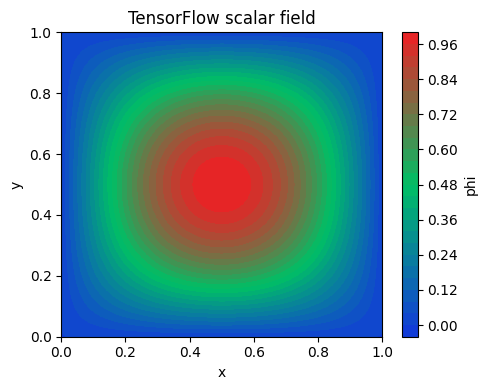

In [4]:
plt.figure(figsize=(5, 4))
plt.contourf(X.numpy(), Y.numpy(), phi.numpy(), levels=30, cmap="cavity_rgb")
plt.colorbar(label="phi")
plt.xlabel("x")
plt.ylabel("y")
plt.title("TensorFlow scalar field")
plt.tight_layout()
plt.show()

**Checkpoint 1 — axes and precision.** What do `phi[10, :]` and `phi[:, 10]` represent? What shape would 20 snapshots of three fields on a 65-by-65 grid have?

<details><summary>Hint and self-check</summary>

With `meshgrid(..., indexing="xy")`, the first index selects a y-row; `phi[10, :]` varies x at fixed y. `phi[:, 10]` varies y at fixed x. Twenty three-channel snapshots have shape `(20, 65, 65, 3)`. Repeat the array conversion with `float64` and compare the reported dtype; more precision also uses more memory.

</details>

## 2. Constants and variables

A `tf.constant` is fixed after construction. A `tf.Variable` stores a value that can be updated with `assign` or `assign_sub`. Learned weights and biases are variables. A CFD state array may change during a solver iteration without being a trainable parameter; being mutable and being trainable are different choices.

`w.assign(2.0)` changes the value of the same variable. `w = tf.constant(2.0)` would replace the Python reference with a different object. Predict the before/after values below.

In [5]:
c = tf.constant(3.0)
w = tf.Variable(0.5)

print("constant c:", c)
print("variable w before:", w)

w.assign(2.0)

print("variable w after:", w)

constant c: tf.Tensor(3.0, shape=(), dtype=float32)
variable w before: <tf.Variable 'Variable:0' shape=() dtype=float32, numpy=0.5>
variable w after: <tf.Variable 'Variable:0' shape=() dtype=float32, numpy=2.0>


## 3. Basic tensor operations

TensorFlow operations look like mathematical operations.  
This is why TensorFlow is useful for scientific machine learning.

Here we build a small field:

$$
f(x,y) = \sin(\pi x)\sin(\pi y).
$$

This is not yet CFD, but it looks like a smooth mode that could appear in a flow field.

In [6]:
f = tf.sin(np.pi * X) * tf.sin(np.pi * Y)
g = X**2 + Y**2
h = f + 0.1 * g

print("f min/max:", float(tf.reduce_min(f)), float(tf.reduce_max(f)))
print("h min/max:", float(tf.reduce_min(h)), float(tf.reduce_max(h)))

f min/max: -8.742277657347586e-08 1.0
h min/max: 0.0 1.050766110420227


## 4. Broadcasting

Broadcasting allows TensorFlow to combine tensors with compatible shapes.

For example:
- a scalar can multiply a full field,
- a 1D vector can be added across one direction,
- a channel weight can scale each field channel.

Broadcasting is powerful, but it can also hide mistakes. Always check shapes.

In [7]:
field = tf.ones((4, 5))
scale = tf.constant(2.0)

print("field shape:", field.shape)
print("scale shape:", scale.shape)
print("result shape:", (scale * field).shape)
print(scale * field)

field shape: (4, 5)
scale shape: ()
result shape: (4, 5)
tf.Tensor(
[[2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2.]
 [2. 2. 2. 2. 2.]], shape=(4, 5), dtype=float32)


### A shape error that produces a plausible number

Subtracting `(4, 1)` and `(4,)` broadcasts to `(4, 4)`, comparing every target with every prediction. TensorFlow can do exactly what was requested while the scientific comparison is wrong. Predict both residual shapes below before running the cell.

In [8]:
targets = tf.constant([[1.0], [2.0], [3.0], [4.0]])
predictions_1d = tf.constant([1.0, 2.0, 3.0, 4.0])
wrong_residual = predictions_1d - targets
correct_residual = predictions_1d[:, None] - targets
print("wrong / correct residual shapes:", wrong_residual.shape, correct_residual.shape)
print("wrong / correct MSE:", float(tf.reduce_mean(wrong_residual**2)),
      float(tf.reduce_mean(correct_residual**2)))
assert wrong_residual.shape == (4, 4)
assert correct_residual.shape == (4, 1)
assert float(tf.reduce_mean(correct_residual**2)) == 0.0

wrong / correct residual shapes: (4, 4) (4, 1)
wrong / correct MSE: 2.5 0.0


## 5. Stacking channels: physically consistent fields as inputs

For Keras convolutional layers, the default ordering is `(batch, Ny, Nx, channels)`. `tf.stack(..., axis=-1)` creates a channel axis; `sample[None, ...]` creates a batch axis. Keeping all channels at the same grid locations matters as much as obtaining the right shape.

Use the dimensionless manufactured streamfunction
\[
\psi=\frac{1}{\pi}\sin(\pi x)\sin(\pi y),\quad
u=\partial_y\psi=\sin(\pi x)\cos(\pi y),\quad
v=-\partial_x\psi=-\cos(\pi x)\sin(\pi y).
\]
Then \(\partial_xu+\partial_yv=0\) and the out-of-plane vorticity is
\(\omega=\partial_xv-\partial_yu=2\pi\sin(\pi x)\sin(\pi y)\).

This is an analytic demonstration field, **not a computed lid-driven cavity solution**. Its impermeable square walls do not impose the cavity's no-slip moving-lid conditions. The next CFD notebook provides the actual cavity reference.

single sample: (65, 65, 3) batch: (1, 65, 65, 3)


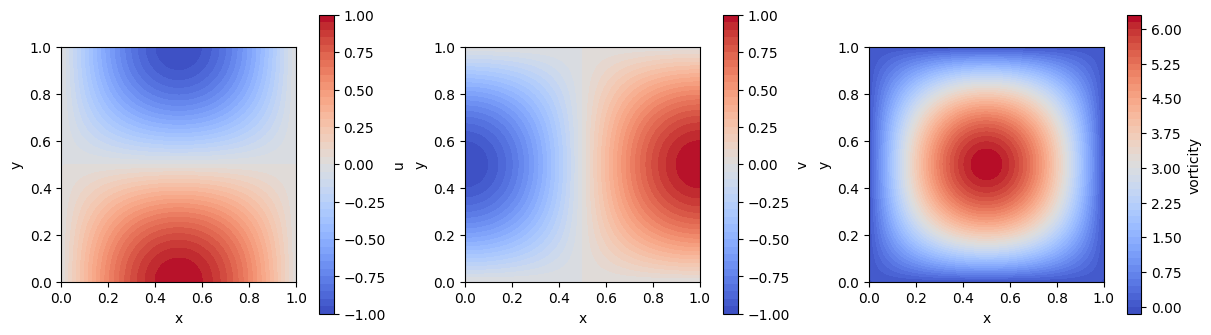

In [9]:
u = tf.sin(np.pi * X) * tf.cos(np.pi * Y)
v = -tf.cos(np.pi * X) * tf.sin(np.pi * Y)
omega = 2.0 * np.pi * tf.sin(np.pi * X) * tf.sin(np.pi * Y)
sample = tf.stack([u, v, omega], axis=-1)
batch = sample[None, ...]
print("single sample:", sample.shape, "batch:", batch.shape)
assert sample.shape == (65, 65, 3)
assert batch.shape == (1, 65, 65, 3)
# Centered differences independently check the analytic identities away from walls.
u_np, v_np, om_np = u.numpy(), v.numpy(), omega.numpy()
h_grid = 1.0 / (N - 1)
du_dy, du_dx = np.gradient(u_np, h_grid, h_grid, edge_order=2)
dv_dy, dv_dx = np.gradient(v_np, h_grid, h_grid, edge_order=2)
interior = np.s_[1:-1, 1:-1]
assert np.max(np.abs((du_dx + dv_dy)[interior])) < 2e-4
assert np.max(np.abs((dv_dx - du_dy - om_np)[interior])) < 3e-3
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout="constrained")
for ax, q, label in zip(axes, [u_np, v_np, om_np], ["u", "v", "vorticity"]):
    cf = ax.contourf(X.numpy(), Y.numpy(), q, levels=41, cmap="coolwarm")
    fig.colorbar(cf, ax=ax, label=label, shrink=0.85)
    ax.set(xlabel="x", ylabel="y", aspect="equal")
plt.show()

**Checkpoint 2 — conservation and channels.** Why can `omega` not be any convenient third array if we call it vorticity? What changes in the batch shape when ten snapshots are stacked with `tf.stack(samples, axis=0)`?

<details><summary>Hint and self-check</summary>

Vorticity is defined by velocity derivatives. Here it must equal \(\partial_xv-\partial_yu\); naming a cosine array “omega” does not make it the curl. Ten aligned snapshots give `(10, 65, 65, 3)`. A learned internal feature channel, unlike a labeled physical vorticity channel, need not have this interpretation.

</details>

## 6. Loss functions and residuals

A supervised **mean squared error (MSE)** loss is
\[\mathcal L=\frac1N\sum_i(y_i^{pred}-y_i^{true})^2.\]
It measures disagreement with labels. Its units are the square of the target's units. Nondimensionalization or declared scaling is needed when combining losses for different physical quantities.

A **partial differential equation (PDE) residual** measures the mismatch in a governing equation. A squared residual can contribute to a loss, but data MSE is not itself a CFD residual. Matching measured velocities does not automatically enforce mass conservation.

Calculate the three squared differences below by hand; their mean is **0.03**. This makes the first loss calculation independently checkable.

In [10]:
y_true = tf.constant([1.0, 2.0, 3.0], dtype=tf.float32)
y_pred = tf.constant([0.8, 2.2, 2.9], dtype=tf.float32)
mse = tf.reduce_mean((y_pred - y_true)**2)
print("MSE loss:", float(mse))
np.testing.assert_allclose(mse.numpy(), 0.03, rtol=1e-5)

MSE loss: 0.029999999329447746


## 7. Automatic differentiation with GradientTape

TensorFlow can compute derivatives automatically.  
This is essential for training neural networks and physics-informed neural networks.

Example:

$$
y = x^2,\qquad \frac{dy}{dx}=2x.
$$

We ask TensorFlow to compute the derivative.

In [11]:
x0 = tf.Variable(3.0)

with tf.GradientTape() as tape:
    y0 = x0**2

dy_dx = tape.gradient(y0, x0)

print("x =", float(x0))
print("y = x^2 =", float(y0))
print("dy/dx =", float(dy_dx))

x = 3.0
y = x^2 = 9.0
dy/dx = 6.0


### Why a gradient can be `None`

A tape watches trainable variables automatically, but not an ordinary constant. `None` means no recorded differentiable path; it does not mean a derivative of zero. Operations must also occur inside the tape and use TensorFlow operations, rather than converting the intermediate result to NumPy.

In [12]:
coordinate = tf.constant(3.0)
with tf.GradientTape() as tape:
    square_unwatched = coordinate**2
unwatched = tape.gradient(square_unwatched, coordinate)
with tf.GradientTape() as tape:
    tape.watch(coordinate)
    square_watched = coordinate**2
watched = tape.gradient(square_watched, coordinate)
print("unwatched / watched derivative:", unwatched, float(watched))
assert unwatched is None
np.testing.assert_allclose(watched.numpy(), 6.0)

unwatched / watched derivative: None 6.0


### Gradient of a loss with respect to model parameters

For \(\hat y_i=ax_i+b\), the chain rule gives
\[
\frac{\partial\mathcal L}{\partial a}=\frac2N\sum_i(\hat y_i-y_i)x_i,
\qquad
\frac{\partial\mathcal L}{\partial b}=\frac2N\sum_i(\hat y_i-y_i).
\]
A gradient points toward increasing loss; gradient descent subtracts a positive learning rate times that gradient. The next cell compares TensorFlow with these formulas before any training. Inputs and labels are fixed; only `a` and `b` are learned.

In [13]:
x_data = tf.constant(np.linspace(0, 1, 50), dtype=tf.float32)
y_data = 2.0 * x_data + 0.5
a = tf.Variable(0.0)
b = tf.Variable(0.0)
with tf.GradientTape() as tape:
    y_pred = a * x_data + b
    loss = tf.reduce_mean((y_pred - y_data)**2)
grad_a, grad_b = tape.gradient(loss, [a, b])
error_np = (y_pred - y_data).numpy()
manual_a = 2.0 * np.mean(error_np * x_data.numpy())
manual_b = 2.0 * np.mean(error_np)
np.testing.assert_allclose([grad_a.numpy(), grad_b.numpy()],
                           [manual_a, manual_b], rtol=1e-6)
print("loss:", float(loss))
print("TensorFlow gradients:", float(grad_a), float(grad_b))
print("chain-rule gradients:", float(manual_a), float(manual_b))

loss: 2.5969390869140625
TensorFlow gradients: -1.8469388484954834 -2.999999761581421
chain-rule gradients: -1.8469387292861938 -3.0


**Checkpoint 3 — sign of the update.** Starting at \(a=b=0\), are the two gradients positive or negative? Does subtracting them increase or decrease the parameters? Use a learning rate of 0.05 for one update and check the MSE before committing to a long loop.

<details><summary>Hint and self-check</summary>

All current predictions are below the positive targets, so both gradients are negative. Subtracting them increases both parameters. This one-step check is repeated explicitly below, independently of the later 100-update loop.

</details>

In [14]:
a_step = float(a) - 0.05*float(grad_a)
b_step = float(b) - 0.05*float(grad_b)
step_loss = float(tf.reduce_mean((a_step*x_data + b_step-y_data)**2))
print("before / after one step:", float(loss), step_loss)
assert step_loss < float(loss)

before / after one step: 2.5969390869140625 2.015603542327881


## 8. Manual training loop

One update is \(a\leftarrow a-\eta\,\partial_a\mathcal L\), and similarly for \(b\). Here \(\eta=0.5\) works for this particular scaled quadratic problem; it is not a general learning-rate rule. Excessively large steps can increase the loss.

The loop below starts from zero and repeats prediction, loss, differentiation and parameter update. It records the **post-update** loss, so the last point describes the printed final parameters. A gradient is recalculated after each update because the loss changes with the parameters. The known answer, \(a=2,b=0.5\), provides a check independent of a visually decreasing curve.

learned a = 1.99887; b = 0.50061
initial/final MSE: 2.59694 / 1.12013e-07


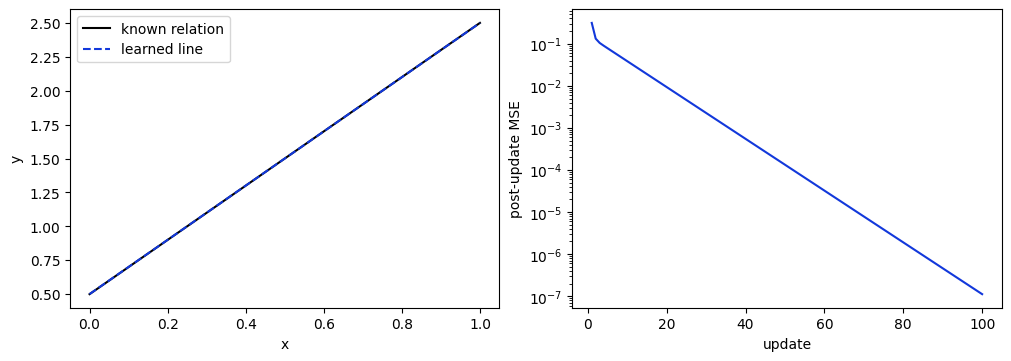

In [15]:
a = tf.Variable(0.0)
b = tf.Variable(0.0)
learning_rate = 0.5
initial_loss = float(tf.reduce_mean((a*x_data + b - y_data)**2))
loss_history = []
for epoch in range(100):
    with tf.GradientTape() as tape:
        prediction = a*x_data + b
        loss = tf.reduce_mean((prediction - y_data)**2)
    grad_a, grad_b = tape.gradient(loss, [a, b])
    a.assign_sub(learning_rate * grad_a)
    b.assign_sub(learning_rate * grad_b)
    loss_history.append(float(tf.reduce_mean((a*x_data + b - y_data)**2)))
print(f"learned a = {float(a):.5f}; b = {float(b):.5f}")
print(f"initial/final MSE: {initial_loss:.6g} / {loss_history[-1]:.6g}")
assert loss_history[-1] < initial_loss * 1e-3
np.testing.assert_allclose([a.numpy(), b.numpy()], [2.0, 0.5], atol=0.02)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
axes[0].plot(x_data, y_data, color="black", label="known relation")
axes[0].plot(x_data, a*x_data+b, "--", label="learned line")
axes[0].set(xlabel="x", ylabel="y")
axes[0].legend()
axes[1].semilogy(np.arange(1, 101), loss_history)
axes[1].set(xlabel="update", ylabel="post-update MSE")
plt.show()

## 9. Keras: a small neural network with separate data roles

Keras is TensorFlow's high-level model interface. A dense layer computes \(Wx+b\); `tanh` supplies nonlinearity. Without nonlinear activations, stacking dense layers still gives one affine map. We approximate \(f(x)=\sin(2\pi x)\) to study this workflow before the multifeature Week 2 problem.

The 201 analytic samples on \([0,1]\) are split by fixed index into **121 training, 40 validation and 40 test locations** with no shared coordinates. Training samples update weights. Validation samples choose when to stop and which weights to restore. Test samples are evaluated once after that choice. This measures interpolation of a known analytic function, not validation against independent CFD or experimental data. It says nothing about accuracy outside \([0,1]\).

The input is `(number_of_samples, 1)`: each row is one scalar input. The hidden layers have 32 units each and the output layer has one unit. `compile` selects the optimizer and loss; `fit` updates trainable weights. Early stopping monitors validation MSE, never test error.

In [16]:
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)
x_all = np.linspace(0, 1, 201, dtype=np.float32).reshape(-1, 1)
y_all = np.sin(2*np.pi*x_all).astype(np.float32)
role = np.arange(len(x_all)) % 5
x_train, y_train = x_all[role < 3], y_all[role < 3]
x_val, y_val = x_all[role == 3], y_all[role == 3]
x_test, y_test = x_all[role == 4], y_all[role == 4]
assert len(x_train) == 121 and len(x_val) == len(x_test) == 40
assert len(set(x_train.ravel()) & set(x_test.ravel())) == 0
assert len(set(x_val.ravel()) & set(x_test.ravel())) == 0
print("train / validation / test:", len(x_train), len(x_val), len(x_test))
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(1,)),
    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(32, activation="tanh"),
    tf.keras.layers.Dense(1)
])
print("trainable parameters:", model.count_params())
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.01), loss="mse")
# A small tf.data pool also makes CPU execution practical on laptops.
options = tf.data.Options()
options.threading.private_threadpool_size = 1
options.threading.max_intra_op_parallelism = 1
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train)).batch(32).with_options(options)
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(40).with_options(options)
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=40, min_delta=1e-6, restore_best_weights=True
)
history = model.fit(train_ds, validation_data=val_ds, epochs=300,
                    callbacks=[early_stop], verbose=0)
print("epochs executed:", len(history.history["loss"]))
print("smallest validation MSE:", min(history.history["val_loss"]))

train / validation / test: 121 40 40
trainable parameters: 1153


D:\ChatGPT Backup\Projects\FlowMLLab\Week01_TensorFlow_20261102\validation-env\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


epochs executed: 300
smallest validation MSE: 0.004441521596163511


held-out test MSE: 0.00448303
held-out relative L2 error: 9.469%


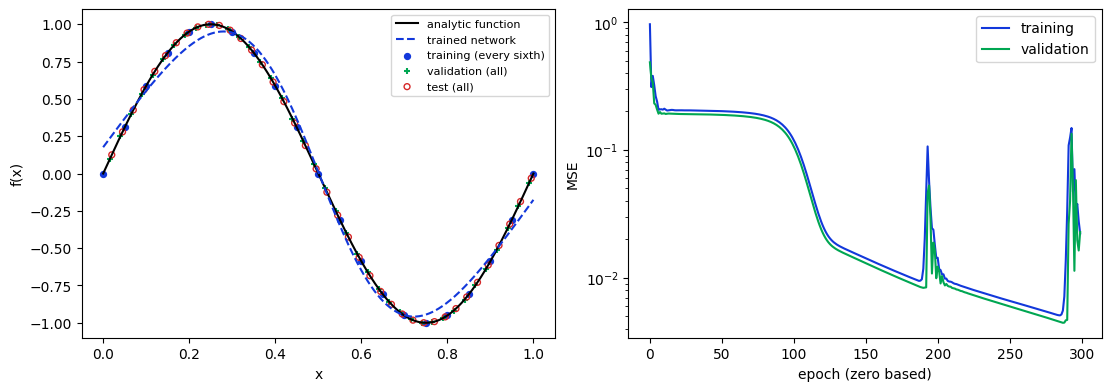

In [17]:
# Weight selection is complete; the test locations have not been used to choose it.
y_nn = model(x_test, training=False).numpy()
test_mse = float(np.mean((y_nn - y_test)**2))
test_relative_l2_percent = 100.0 * np.linalg.norm(y_nn-y_test) / np.linalg.norm(y_test)
print(f"held-out test MSE: {test_mse:.6g}")
print(f"held-out relative L2 error: {test_relative_l2_percent:.3f}%")
assert np.isfinite(test_mse) and np.isfinite(test_relative_l2_percent)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
x_plot = np.linspace(0, 1, 401, dtype=np.float32).reshape(-1, 1)
axes[0].plot(x_plot, np.sin(2*np.pi*x_plot), color="black", label="analytic function")
axes[0].plot(x_plot, model(x_plot, training=False).numpy(), "--", label="trained network")
axes[0].scatter(x_train[::6], y_train[::6], s=18, marker="o", label="training (every sixth)")
axes[0].scatter(x_val, y_val, s=16, marker="+", label="validation (all)")
axes[0].scatter(x_test, y_test, s=18, facecolors="none", edgecolors="tab:red", label="test (all)")
axes[0].set(xlabel="x", ylabel="f(x)")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].semilogy(history.history["loss"], label="training")
axes[1].semilogy(history.history["val_loss"], label="validation")
axes[1].set(xlabel="epoch (zero based)", ylabel="MSE")
axes[1].legend()
plt.show()

**Checkpoint 4 — what did the network learn?** The field is analytic and the held-out coordinates lie inside the sampled interval. Explain why this is an interpolation check. Would success justify a prediction at \(x=2\), a new fluid, or a new Reynolds number?

<details><summary>Hint and self-check</summary>

No. None of those changes is tested. Do not retrain repeatedly to improve this test score: that would turn the test set into a model-selection set. Compare different architectures using validation data and preserve a separate final test if doing a new study.

</details>

## 10. GradientTape for physics residuals

A physics-informed neural network (PINN) uses derivatives of its output to form equation residuals. First verify the differentiation machinery using a known function:
\[u(x)=\sin(\pi x),\qquad u''(x)+\pi^2\sin(\pi x)=0.\]

The inner tape records \(u\) and obtains \(u'\). The outer tape must record the calculation of \(u'\) to obtain \(u''\). We explicitly watch the coordinates because constants are not watched automatically. The next cell uses `float64` for a stringent analytic check. It does **not** train a PINN or establish that a learned solution satisfies this equation.

`gradient` of a vector target sums its contributions. It gives the desired pointwise derivative here because each output row depends only on the corresponding coordinate row. Layers that couple samples require an appropriate Jacobian calculation instead.

In [18]:
x_phys = tf.constant(np.linspace(0, 1, 100).reshape(-1, 1), dtype=tf.float64)
with tf.GradientTape() as tape2:
    tape2.watch(x_phys)
    with tf.GradientTape() as tape1:
        tape1.watch(x_phys)
        u_exact = tf.sin(np.pi*x_phys)
    du_dx = tape1.gradient(u_exact, x_phys)
d2u_dx2 = tape2.gradient(du_dx, x_phys)
residual = d2u_dx2 + np.pi**2*tf.sin(np.pi*x_phys)
max_residual = float(tf.reduce_max(tf.abs(residual)))
np.testing.assert_allclose(du_dx.numpy(), np.pi*np.cos(np.pi*x_phys.numpy()), atol=1e-12)
assert max_residual < 1e-10
print("maximum analytic ODE residual:", max_residual)

maximum analytic ODE residual: 1.7763568394002505e-15


Automatic differentiation and finite differences answer different computational questions. The tape differentiates the composed function; a finite-difference stencil approximates derivatives from sampled values and adds discretization error. Neither proves a trained network represents the physical solution. Both need checks against a known answer.

### A small value error does not guarantee a small derivative error

The sine network was trained on function values only. Its analytical target is now \(\sin(2\pi x)\), whose first derivative is \(2\pi\cos(2\pi x)\) and whose equation residual is \(u''+(2\pi)^2\sin(2\pi x)\). The next plot compares its learned derivative with the analytic derivative and shows its equation residual over the interval. This is a diagnostic after training, not an extra training loss or a test used to select weights. An accurate value fit can still have derivative errors, particularly near the ends. No claim of a trained PINN is made.

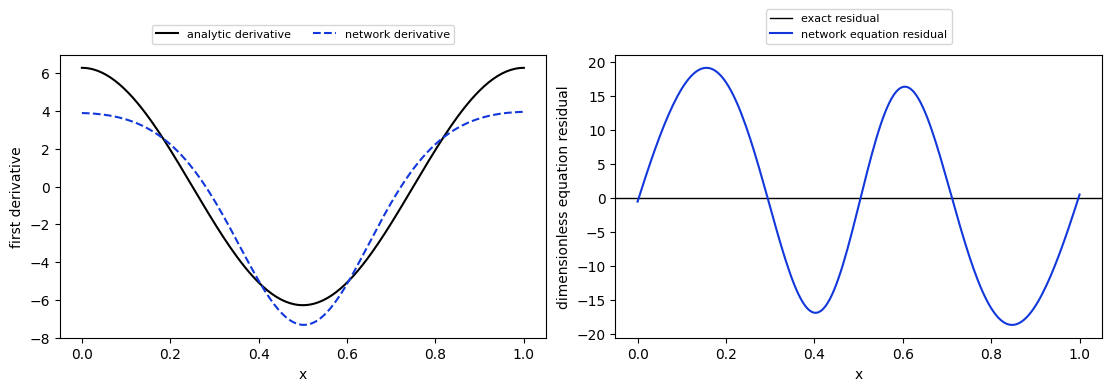

In [19]:
probe_x = tf.constant(np.linspace(0, 1, 201).reshape(-1, 1), dtype=tf.float32)
with tf.GradientTape() as second_tape:
    second_tape.watch(probe_x)
    with tf.GradientTape() as first_tape:
        first_tape.watch(probe_x)
        probe_u = model(probe_x, training=False)
    learned_slope = first_tape.gradient(probe_u, probe_x)
learned_curvature = second_tape.gradient(learned_slope, probe_x)
learned_residual = learned_curvature + (2*np.pi)**2*tf.sin(2*np.pi*probe_x)
assert bool(tf.reduce_all(tf.math.is_finite(learned_residual)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
axes[0].plot(probe_x, 2*np.pi*np.cos(2*np.pi*probe_x.numpy()), color="black", label="analytic derivative")
axes[0].plot(probe_x, learned_slope.numpy(), "--", label="network derivative")
axes[0].set(xlabel="x", ylabel="first derivative")
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=8)
axes[1].axhline(0, color="black", linewidth=1, label="exact residual")
axes[1].plot(probe_x, learned_residual.numpy(), label="network equation residual")
axes[1].set(xlabel="x", ylabel="dimensionless equation residual")
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), fontsize=8)
plt.show()

### A fluid-mechanics residual with a known answer

For steady, fully developed incompressible flow between parallel plates at \(y=\pm1\), a dimensionless momentum balance can be written
\[u''(y)+2=0,\qquad u(-1)=u(1)=0.\]
The analytic solution is \(u=1-y^2\). The constant 2 represents a fixed nondimensional pressure-gradient/viscosity ratio; this is a laminar channel example, not the rarefied-flow relation used in Week 2.

Check both the equation and wall values. A small equation residual alone is insufficient: \(1-y^2+0.3y\) satisfies the same differential equation but violates the no-slip wall conditions. This distinction motivates separate data, equation and boundary-condition terms in a PINN loss.

max channel residual: 0.0
correct / offset-profile wall velocities: [0. 0.] [-0.3  0.3]


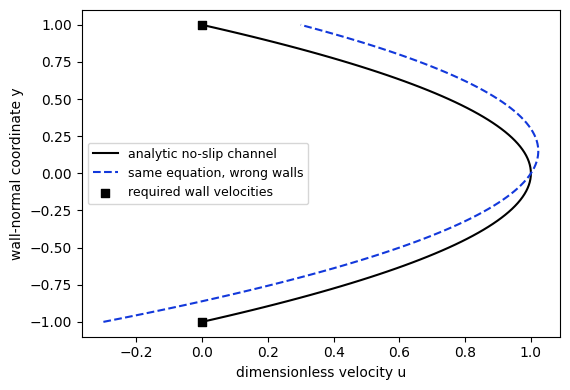

In [20]:
y_channel = tf.constant(np.linspace(-1, 1, 101).reshape(-1, 1), dtype=tf.float64)
with tf.GradientTape() as outer:
    outer.watch(y_channel)
    with tf.GradientTape() as inner:
        inner.watch(y_channel)
        u_channel = 1.0-y_channel**2
        u_wrong_walls = 1.0-y_channel**2+0.3*y_channel
    slope = inner.gradient(u_channel, y_channel)
# A separate analytic boundary comparison avoids reusing a non-persistent tape.
curvature = outer.gradient(slope, y_channel)
channel_residual = curvature + 2.0
wall_values = tf.gather(u_channel, [0, 100]).numpy().ravel()
wrong_wall_values = tf.gather(u_wrong_walls, [0, 100]).numpy().ravel()
print("max channel residual:", float(tf.reduce_max(tf.abs(channel_residual))))
print("correct / offset-profile wall velocities:", wall_values, wrong_wall_values)
assert float(tf.reduce_max(tf.abs(channel_residual))) < 1e-12
np.testing.assert_allclose(wall_values, [0.0, 0.0], atol=1e-12)
assert np.max(np.abs(wrong_wall_values)) > 0.29
plt.figure(figsize=(5.8, 4))
plt.plot(u_channel.numpy(), y_channel.numpy(), color="black", label="analytic no-slip channel")
plt.plot(u_wrong_walls.numpy(), y_channel.numpy(), "--", label="same equation, wrong walls")
plt.scatter([0, 0], [-1, 1], marker="s", color="black", label="required wall velocities")
plt.xlabel("dimensionless velocity u")
plt.ylabel("wall-normal coordinate y")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 11. A small convolutional model for field data

A convolutional neural network (CNN) uses local filters with shared weights. With `padding="same"`, stride one and the odd kernel used here, its spatial size is preserved. The first two layers create 16 internal feature channels; the last layer returns one channel.

The four random input images below are **untrained shape probes**. No physical training or test dataset is used, and the random outputs are not flow predictions. Record `(batch, Ny, Nx, channels)` at both ends. A field-to-field model needs physical paired data and validation before its outputs can be interpreted as a solution.

In [21]:
N = 32
dummy_input = tf.random.normal((4, N, N, 1))  # batch of 4 scalar fields

cnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(N, N, 1)),
    tf.keras.layers.Conv2D(16, kernel_size=3, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(16, kernel_size=3, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(1, kernel_size=3, padding="same")
])

dummy_output = cnn(dummy_input)

print("input shape :", dummy_input.shape)
print("output shape:", dummy_output.shape)

input shape : (4, 32, 32, 1)
output shape: (4, 32, 32, 1)


### Practice without changing the worked reference

Choose one task in a new cell:

- Change the manual fit to \(y=3x-0.2\). Predict the new final coefficients before running.
- Evaluate the shape error with five samples instead of four. Explain why the wrong residual contains 25 entries.
- Set `activation=None` in a separate sine model. Explain why depth alone cannot reproduce the sine curve.
- Add \(cy\) to the channel profile. Derive its second derivative and its two wall values for arbitrary \(c\).

Write down what you changed, your prediction, the observed result and an explanation. These are learning exercises rather than additional required submissions.

### Troubleshooting

| Symptom | Check and repair |
|---|---|
| `ModuleNotFoundError: tensorflow` | Install in the active kernel, restart it and rerun setup. |
| `NameError` for an earlier variable | Run from the top; executing out of order loses the dependency chain. |
| MSE looks reasonable but samples do not match | Print both shapes; reshape targets and predictions consistently. |
| Mixed `float32` / `float64` operation | Choose one dtype for that calculation and convert explicitly. |
| Gradient is `None` | Watch constants; keep operations inside the tape and avoid a NumPy conversion there. |
| Loss diverges or becomes non-finite | Restore the worked settings, inspect scaling and reduce the learning rate in a separate experiment. |
| Windows installation reports a very long missing filename | Create the Python environment in a short path, then reinstall; see the official TensorFlow installation guide. |
| No GPU appears | Use the CPU; this introductory lab does not require GPU acceleration. |
| Colab still shows the older text | Open the GitHub badge afresh; a saved Drive copy is separate. |

## 12. Required student deliverables and Week 2 readiness

Keep the original deliverables: a TensorFlow field plot; an explanation of CFD tensor shapes; the manual linear-fit loop and final \(a,b\); the Keras sine-function plots; the automatic-differentiation residual check; a paragraph distinguishing CFD residuals from losses; and a paragraph explaining field channels as model inputs. Include your executed cells and use your own words.

The added checkpoints help you explain those results. For the network figure, report training/validation/test counts, the held-out relative error and the fact that the reference is analytic. Do not report the final training loss as test accuracy.

**Ready to move to Week 2?** You should be able to:

1. construct an input array of shape `(samples, features)` and a target of shape `(samples, 1)`;
2. explain why a gradient-descent update subtracts the gradient;
3. identify trainable weights and the fixed training labels;
4. distinguish training, validation and untouched test data;
5. run this notebook from a fresh kernel without skipping a definition.

If you can do these, start [AI in Fluids — Week 2](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week02/AI_in_Fluids_Week2_Colab_Expanded.ipynb). Its first two sections revisit the forward pass and one-neuron update. You can return to the channel-residual and CNN examples while studying later physics-informed and field-to-field models. The examples here establish the programming workflow; they do not replace CFD validation.

## Further reading

Use these references to look up an unfamiliar API after completing the worked examples:

- [TensorFlow tensors](https://www.tensorflow.org/guide/tensor): ranks, shapes and dtypes.
- [Automatic differentiation](https://www.tensorflow.org/guide/autodiff): watched values, gradients and disconnected paths.
- [Keras Sequential models](https://www.tensorflow.org/guide/keras/sequential_model): inputs, dense layers and trainable parameters.
- [Training and evaluation](https://www.tensorflow.org/guide/keras/training_with_built_in_methods): losses, validation and callbacks.

The manufactured-field and channel examples above provide analytic checks for this notebook. Manuscript CFD comparisons remain owned by the numerical notebooks listed below.

## Article-output contract

<!-- MIE690A article-aligned validation v3 -->

**Role:** Foundational or supporting notebook; see ARTICLE_FIGURE_MAP.md for its evidence dependency.

All manuscript-facing figures must be generated from retained numerical/model outputs through the documented notebook or shared helper, saved under `results/`, and accompanied by machine-readable metrics. Do not redraw curves by eye or substitute a screenshot for a solver-to-reference comparison. The complete ownership table and exact output filenames are in [`ARTICLE_FIGURE_MAP.md`](../../ARTICLE_FIGURE_MAP.md).
